In [116]:
# Importing functions
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
from scipy.stats import spearmanr

# 1. Geographic Accessibility Analysis - Distance to the Nearest Supermarket

In [79]:
# Load supermarket locations
stores = gpd.read_file(
    "../data/processed/perth_supermarkets_clean.geojson"
)

In [80]:
# Load the downloaded ZIP file
sa2 = gpd.read_file(
    "../data/raw/SA2_2021_AUST_SHP_GDA2020.zip"
)

print(sa2.shape)
print(sa2.columns.tolist())

sa2.head()

(2473, 17)
['SA2_CODE21', 'SA2_NAME21', 'CHG_FLAG21', 'CHG_LBL21', 'SA3_CODE21', 'SA3_NAME21', 'SA4_CODE21', 'SA4_NAME21', 'GCC_CODE21', 'GCC_NAME21', 'STE_CODE21', 'STE_NAME21', 'AUS_CODE21', 'AUS_NAME21', 'AREASQKM21', 'LOCI_URI21', 'geometry']


,SA2_CODE21,SA2_NAME21,CHG_FLAG21,CHG_LBL21,SA3_CODE21,SA3_NAME21,SA4_CODE21,SA4_NAME21,GCC_CODE21,GCC_NAME21,STE_CODE21,STE_NAME21,AUS_CODE21,AUS_NAME21,AREASQKM21,LOCI_URI21,geometry
0,101021007,Braidwood,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,3418.3525,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.58424 -35.44426, 149.58444 -35.4..."
1,101021008,Karabar,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,6.9825,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.21899 -35.36738, 149.218 -35.366..."
2,101021009,Queanbeyan,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,4.7620,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.21326 -35.34325, 149.21619 -35.3..."
3,101021010,Queanbeyan - East,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,13.0032,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.24034 -35.34781, 149.24024 -35.3..."
4,101021012,Queanbeyan West - Jerrabomberra,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,13.6748,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.19572 -35.36126, 149.1997 -35.35..."


In [81]:
# Filter the data to only Greater Perth Area
perth_sa2 = sa2[
    sa2["GCC_NAME21"] == "Greater Perth"
].copy()

print(f"Number of SA2 areas: {len(perth_sa2)}")
perth_sa2.head()

Number of SA2 areas: 185


,SA2_CODE21,SA2_NAME21,CHG_FLAG21,CHG_LBL21,SA3_CODE21,SA3_NAME21,SA4_CODE21,SA4_NAME21,GCC_CODE21,GCC_NAME21,STE_CODE21,STE_NAME21,AUS_CODE21,AUS_NAME21,AREASQKM21,LOCI_URI21,geometry
1915,502011021,Dawesville - Bouvard,0,No change,50201,Mandurah,502,Mandurah,5GPER,Greater Perth,5,Western Australia,AUS,Australia,97.9248,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((115.62127 -32.626, 115.62148 -32.625..."
1916,502011022,Falcon - Wannanup,0,No change,50201,Mandurah,502,Mandurah,5GPER,Greater Perth,5,Western Australia,AUS,Australia,9.5893,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((115.64449 -32.58543, 115.64458 -32.5..."
1917,502011023,Greenfields,0,No change,50201,Mandurah,502,Mandurah,5GPER,Greater Perth,5,Western Australia,AUS,Australia,9.9609,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((115.74699 -32.51601, 115.74678 -32.5..."
1918,502011024,Halls Head - Erskine,0,No change,50201,Mandurah,502,Mandurah,5GPER,Greater Perth,5,Western Australia,AUS,Australia,14.2469,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"MULTIPOLYGON (((115.70371 -32.56492, 115.7037 ..."
1919,502011025,Mandurah,0,No change,50201,Mandurah,502,Mandurah,5GPER,Greater Perth,5,Western Australia,AUS,Australia,8.3954,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((115.71226 -32.52588, 115.71212 -32.5..."


In [82]:
# Missing values
print("Missing values:")
print(perth_sa2.isna().sum())

# Duplicate identifiers
print("\nDuplicate SA2 codes:")
print(perth_sa2["SA2_CODE21"].duplicated().sum())

Missing values:
SA2_CODE21    0
SA2_NAME21    0
CHG_FLAG21    0
CHG_LBL21     0
SA3_CODE21    0
SA3_NAME21    0
SA4_CODE21    0
SA4_NAME21    0
GCC_CODE21    0
GCC_NAME21    0
STE_CODE21    0
STE_NAME21    0
AUS_CODE21    0
AUS_NAME21    0
AREASQKM21    0
LOCI_URI21    0
geometry      0
dtype: int64

Duplicate SA2 codes:
0


The SA2 dataset contains no missing values or duplicate geographic identifiers. This indicates that the records are complete and can be uniquely identified for subsequent spatial analysis and integration with Census data.

Further checks will be conducted to verify the validity of geographic boundaries and land area measurements.

In [83]:
print("Invalid geometries:", (~perth_sa2.geometry.is_valid).sum())

Invalid geometries: 0


No missing values, duplicate SA2 identifiers, or invalid geometries were found, indicating that the geographic boundaries are suitable for further spatial analysis.

In [84]:
print("Supermarket CRS:", stores.crs)
print("SA2 CRS:", perth_sa2.crs)

Supermarket CRS: EPSG:4326
SA2 CRS: EPSG:7844


In [85]:
# Convert SA2 boundaries to the same CRS as supermarkets
perth_sa2 = perth_sa2.to_crs(stores.crs)

print("Supermarket CRS:", stores.crs)
print("SA2 CRS:", perth_sa2.crs)

Supermarket CRS: EPSG:4326
SA2 CRS: EPSG:4326


In [86]:
stores_m = stores.to_crs(epsg=7850)
perth_sa2_m = perth_sa2.to_crs(epsg=7850)

The supermarket and SA2 datasets use different geographic coordinate systems. The SA2 boundaries were converted to match the supermarket dataset (EPSG:4326) to ensure consistency during mapping and spatial analysis.

A projected coordinate system will be used later when calculating distances between residential areas and supermarkets.

In [87]:
perth_sa2_clean = perth_sa2[
    ["SA2_CODE21", "SA2_NAME21", "AREASQKM21", "geometry"]
].copy()

perth_sa2_clean.head()

,SA2_CODE21,SA2_NAME21,AREASQKM21,geometry
1915,502011021,Dawesville - Bouvard,97.9248,"POLYGON ((115.62127 -32.626, 115.62148 -32.625..."
1916,502011022,Falcon - Wannanup,9.5893,"POLYGON ((115.64449 -32.58543, 115.64458 -32.5..."
1917,502011023,Greenfields,9.9609,"POLYGON ((115.74699 -32.51601, 115.74678 -32.5..."
1918,502011024,Halls Head - Erskine,14.2469,"MULTIPOLYGON (((115.70371 -32.56492, 115.7037 ..."
1919,502011025,Mandurah,8.3954,"POLYGON ((115.71226 -32.52588, 115.71212 -32.5..."


We retain the SA2 code for joining Census data later, the name for identifying areas, the land area for geographic context, and the geometry for spatial analysis.

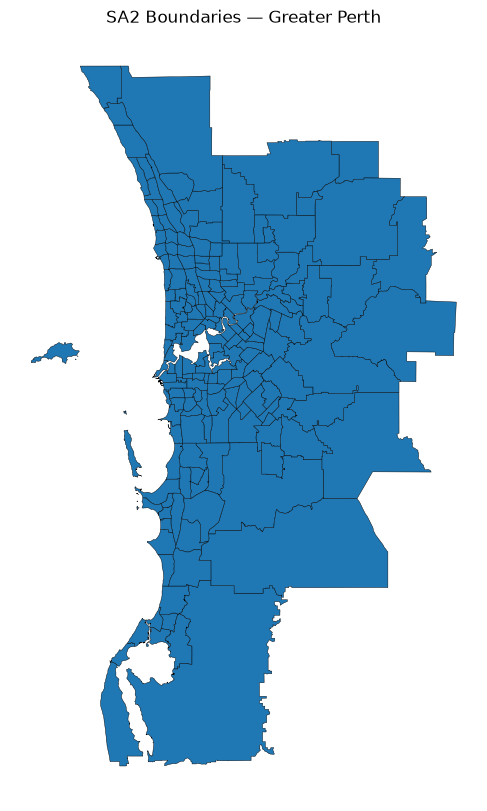

In [88]:
fig, ax = plt.subplots(figsize=(10, 10))

perth_sa2_clean.plot(
    ax=ax,
    edgecolor="black",
    linewidth=0.3
)

ax.set_title("SA2 Boundaries — Greater Perth")
ax.set_axis_off()

plt.show()

The SA2 boundaries were plotted to visualise the geographic areas included in Greater Perth.

These boundaries will serve as the basis for comparing supermarket accessibility across different communities and integrating socioeconomic data later in the analysis.

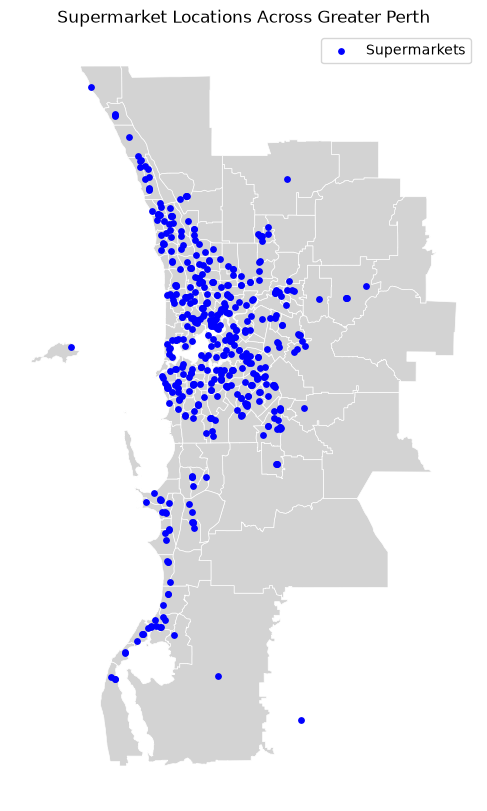

In [89]:
# Ensure both datasets use the same CRS
stores = stores.to_crs(perth_sa2_clean.crs)

fig, ax = plt.subplots(figsize=(12, 10))

# Plot Greater Perth SA2 boundaries
perth_sa2_clean.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.5
)

# Overlay supermarket locations
stores.plot(
    ax=ax,
    color="blue",
    markersize=15,
    label="Supermarkets"
)

ax.set_title("Supermarket Locations Across Greater Perth")
ax.set_axis_off()
ax.legend()

plt.show()

The map shows that supermarkets are more concentrated around central Perth and surrounding urban areas, while locations become more scattered towards the outer suburbs, particularly in the east.

However, fewer supermarkets do not necessarily indicate poor accessibility, as population distribution and travel distances must also be considered.

Further analysis is needed to identify which communities have limited supermarket access and whether these areas experience socioeconomic disadvantage.

In [90]:
# Create representative points for each SA2
sa2_points = perth_sa2_m.copy()
sa2_points["geometry"] = sa2_points.geometry.representative_point()

# Ensure supermarkets are represented as points
stores_m = stores_m.copy()
stores_m["geometry"] = stores_m.geometry.representative_point()

In [91]:
nearest_stores = gpd.sjoin_nearest(
    sa2_points,
    stores_m[["geometry"]],
    how="left",
    distance_col="distance_m"
)

# Convert metres to kilometres
nearest_stores["distance_km"] = nearest_stores["distance_m"] / 1000

# Examine areas furthest from supermarkets
display(
    nearest_stores[
        ["SA2_NAME21", "distance_km"]
    ].sort_values("distance_km", ascending=False).head(10)
)

,SA2_NAME21,distance_km
2051,Serpentine - Jarrahdale,18.209929
2015,Ashendon - Lesley,15.839650
1951,Avon Valley National Park,15.742833
1955,Gidgegannup,13.977239
1945,Chidlow,12.610592
1948,Malmalling - Reservoir,12.358861
2007,Carabooda - Pinjar,9.446313
1959,Melaleuca - Lexia,7.952079
1915,Dawesville - Bouvard,7.382523
1964,Walyunga National Park,6.306134


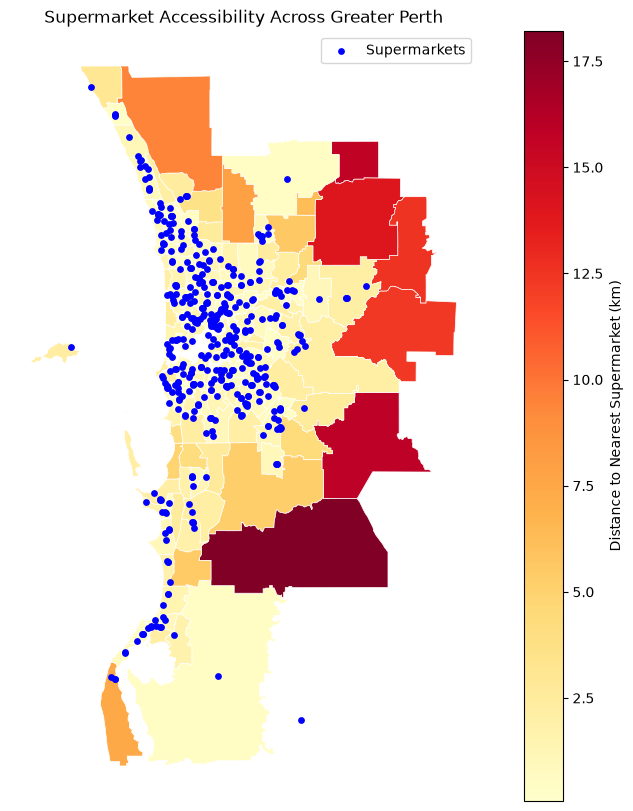

In [92]:
# Add calculated distances to the original SA2 boundaries
distance_by_sa2 = (
    nearest_stores.groupby("SA2_CODE21")["distance_km"].min()
)

perth_sa2_map = perth_sa2_clean.join(
    distance_by_sa2,
    on="SA2_CODE21"
)

# Ensure both datasets use the same CRS
stores = stores.to_crs(perth_sa2_map.crs)

fig, ax = plt.subplots(figsize=(12, 10))

# Plot SA2 boundaries coloured by distance
perth_sa2_map.plot(
    column="distance_km",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={"label": "Distance to Nearest Supermarket (km)"}
)

# Overlay supermarket locations
stores.plot(
    ax=ax,
    color="blue",
    markersize=15,
    label="Supermarkets"
)

ax.set_title("Supermarket Accessibility Across Greater Perth")
ax.set_axis_off()
ax.legend()

plt.show()

The map shows that central Perth generally has shorter distances to supermarkets, while several outer areas, particularly in the east and southeast, have greater distances.

This suggests that supermarket accessibility varies geographically across Greater Perth.

However, the distances are based on representative points within each SA2 rather than actual residential locations. Population distribution and transportation accessibility must therefore be considered before identifying potential food deserts.

# 2. Population Distribution and Supermarket Accessibility

In [93]:
# Load the downloaded Census ZIP file
zip_path = "../data/raw/2021_GCP_SA2_for_WA_short-header.zip"

with zipfile.ZipFile(zip_path) as z:
    # Find the population table (G01)
    file = next(
        name for name in z.namelist()
        if "G01" in name.upper() and name.lower().endswith(".csv")
    )

    population = pd.read_csv(z.open(file))

print(population.shape)
print(population.columns.tolist())

population.head()

(267, 109)
['SA2_CODE_2021', 'Tot_P_M', 'Tot_P_F', 'Tot_P_P', 'Age_0_4_yr_M', 'Age_0_4_yr_F', 'Age_0_4_yr_P', 'Age_5_14_yr_M', 'Age_5_14_yr_F', 'Age_5_14_yr_P', 'Age_15_19_yr_M', 'Age_15_19_yr_F', 'Age_15_19_yr_P', 'Age_20_24_yr_M', 'Age_20_24_yr_F', 'Age_20_24_yr_P', 'Age_25_34_yr_M', 'Age_25_34_yr_F', 'Age_25_34_yr_P', 'Age_35_44_yr_M', 'Age_35_44_yr_F', 'Age_35_44_yr_P', 'Age_45_54_yr_M', 'Age_45_54_yr_F', 'Age_45_54_yr_P', 'Age_55_64_yr_M', 'Age_55_64_yr_F', 'Age_55_64_yr_P', 'Age_65_74_yr_M', 'Age_65_74_yr_F', 'Age_65_74_yr_P', 'Age_75_84_yr_M', 'Age_75_84_yr_F', 'Age_75_84_yr_P', 'Age_85ov_M', 'Age_85ov_F', 'Age_85ov_P', 'Counted_Census_Night_home_M', 'Counted_Census_Night_home_F', 'Counted_Census_Night_home_P', 'Count_Census_Nt_Ewhere_Aust_M', 'Count_Census_Nt_Ewhere_Aust_F', 'Count_Census_Nt_Ewhere_Aust_P', 'Indigenous_psns_Aboriginal_M', 'Indigenous_psns_Aboriginal_F', 'Indigenous_psns_Aboriginal_P', 'Indig_psns_Torres_Strait_Is_M', 'Indig_psns_Torres_Strait_Is_F', 'Indig_psns

,SA2_CODE_2021,Tot_P_M,Tot_P_F,Tot_P_P,Age_0_4_yr_M,Age_0_4_yr_F,Age_0_4_yr_P,Age_5_14_yr_M,Age_5_14_yr_F,Age_5_14_yr_P,...,High_yr_schl_comp_Yr_8_belw_P,High_yr_schl_comp_D_n_g_sch_M,High_yr_schl_comp_D_n_g_sch_F,High_yr_schl_comp_D_n_g_sch_P,Count_psns_occ_priv_dwgs_M,Count_psns_occ_priv_dwgs_F,Count_psns_occ_priv_dwgs_P,Count_Persons_other_dwgs_M,Count_Persons_other_dwgs_F,Count_Persons_other_dwgs_P
0,501011001,3291,3307,6595,202,159,370,447,439,881,...,87,4,5,8,2707,2840,5550,432,431,857
1,501011003,5942,5958,11900,311,342,649,913,843,1755,...,120,6,3,8,4964,5193,10158,833,933,1772
2,501011004,5094,5099,10193,314,298,618,801,753,1556,...,132,7,5,9,4246,4453,8706,652,657,1304
3,501011293,4564,4794,9359,199,214,412,612,572,1178,...,242,22,3,29,4024,4402,8419,330,298,621
4,501011294,9192,10095,19292,491,477,965,1336,1296,2630,...,542,46,33,80,8116,9143,17268,775,949,1724


In [94]:
print("Dataset shape:", population.shape)

print("\nMissing SA2 codes:")
print(population["SA2_CODE_2021"].isna().sum())

print("\nDuplicate SA2 codes:")
print(population["SA2_CODE_2021"].duplicated().sum())

print("\nMissing population values:")
print(population["Tot_P_P"].isna().sum())

print("\nPopulation summary:")
print(population["Tot_P_P"].describe())

Dataset shape: (267, 109)

Missing SA2 codes:
0

Duplicate SA2 codes:
0

Missing population values:
0

Population summary:
count      267.000000
mean      9962.689139
std       6227.051123
min          0.000000
25%       5138.500000
50%       9816.000000
75%      13904.000000
max      26046.000000
Name: Tot_P_P, dtype: float64


In [95]:
# Identify SA2 areas with no recorded population
zero_population = population[
    population["Tot_P_P"] == 0
]

print("SA2 areas with zero population:", len(zero_population))

display(
    zero_population[["SA2_CODE_2021", "Tot_P_P"]]
)

SA2 areas with zero population: 8


,SA2_CODE_2021,Tot_P_P
67,504031064,0
72,504031069,0
92,505021087,0
133,506021120,0
165,507011151,0
218,509011235,0
253,511031281,0
256,511031284,0


The dataset contains 267 SA2 records with no missing values or duplicate identifiers.

Eight SA2 areas have a recorded population of zero, potentially representing non-residential areas such as national parks or industrial zones.

These areas will be retained in the dataset but excluded from residential accessibility assessments, as our objective is to identify populated communities with limited access to supermarkets.

In [96]:
population_clean = population[
    ["SA2_CODE_2021", "Tot_P_P"]
].copy()

population_clean = population_clean.rename(columns={
    "SA2_CODE_2021": "SA2_CODE21",
    "Tot_P_P": "population"
})

population_clean.head()

,SA2_CODE21,population
0,501011001,6595
1,501011003,11900
2,501011004,10193
3,501011293,9359
4,501011294,19292


Only the SA2 identifier and total population were retained, as these are the variables required to assess population distribution and its relationship with supermarket accessibility.

The columns were also renamed for consistency and easier integration with the geographic dataset.

In [97]:
# Ensure both datasets have matching identifier types
perth_sa2_clean["SA2_CODE21"] = perth_sa2_clean["SA2_CODE21"].astype(str)
population_clean["SA2_CODE21"] = population_clean["SA2_CODE21"].astype(str)

# Merge population data with geographic boundaries
perth_population = perth_sa2_clean.merge(
    population_clean,
    on="SA2_CODE21",
    how="left",
    validate="one_to_one"
)

# Check that the data merged correctly
print("Total SA2 areas:", len(perth_population))
print("Unmatched population records:", perth_population["population"].isna().sum())

perth_population.head()

Total SA2 areas: 185
Unmatched population records: 0


,SA2_CODE21,SA2_NAME21,AREASQKM21,geometry,population
0,502011021,Dawesville - Bouvard,97.9248,"POLYGON ((115.62127 -32.626, 115.62148 -32.625...",8498
1,502011022,Falcon - Wannanup,9.5893,"POLYGON ((115.64449 -32.58543, 115.64458 -32.5...",9664
2,502011023,Greenfields,9.9609,"POLYGON ((115.74699 -32.51601, 115.74678 -32.5...",9869
3,502011024,Halls Head - Erskine,14.2469,"MULTIPOLYGON (((115.70371 -32.56492, 115.7037 ...",19905
4,502011025,Mandurah,8.3954,"POLYGON ((115.71226 -32.52588, 115.71212 -32.5...",10256


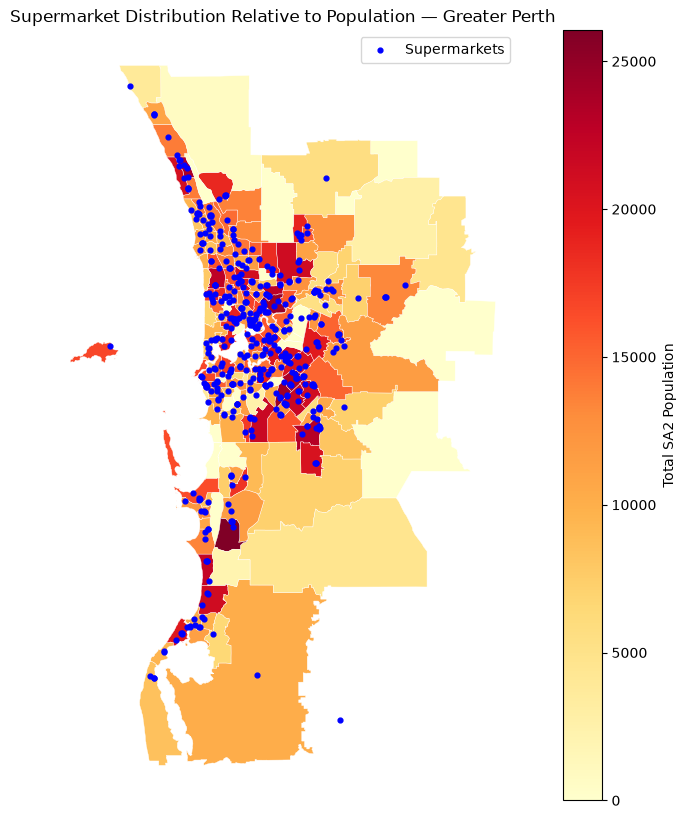

In [98]:
# Ensure both datasets use the same CRS
stores_plot = stores.to_crs(perth_population.crs)

fig, ax = plt.subplots(figsize=(12, 10))

# Plot SA2 boundaries coloured by population
perth_population.plot(
    column="population",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    legend_kwds={"label": "Total SA2 Population"}
)

# Overlay supermarket locations
stores_plot.plot(
    ax=ax,
    color="blue",
    markersize=12,
    label="Supermarkets",
    zorder=3
)

ax.set_title("Supermarket Distribution Relative to Population — Greater Perth")
ax.set_axis_off()
ax.legend()

plt.show()

The map shows that supermarkets are generally concentrated around central Perth, where many of the more populated areas are also located.

However, some populated areas towards eastern Greater Perth appear to have fewer supermarkets nearby, suggesting potential gaps in accessibility.

Further analysis is required to determine whether these communities experience greater distances to supermarkets and whether socioeconomic or transportation barriers contribute to limited access.

In [99]:
# Retain one nearest-supermarket distance per SA2
distance_by_sa2 = (
    nearest_stores.groupby("SA2_CODE21", as_index=False)["distance_km"]
    .min()
)

# Ensure identifiers have the same data type
distance_by_sa2["SA2_CODE21"] = distance_by_sa2["SA2_CODE21"].astype(str)
perth_population["SA2_CODE21"] = perth_population["SA2_CODE21"].astype(str)

# Combine population with supermarket accessibility
perth_accessibility = perth_population.merge(
    distance_by_sa2,
    on="SA2_CODE21",
    how="left",
    validate="one_to_one"
)

# Verify the merge
print("Total SA2 areas:", len(perth_accessibility))
print("Missing population:", perth_accessibility["population"].isna().sum())
print("Missing distances:", perth_accessibility["distance_km"].isna().sum())

display(
    perth_accessibility[
        ["SA2_NAME21", "population", "distance_km"]
    ].head()
)

Total SA2 areas: 185
Missing population: 0
Missing distances: 0


,SA2_NAME21,population,distance_km
0,Dawesville - Bouvard,8498,7.382523
1,Falcon - Wannanup,9664,0.779720
2,Greenfields,9869,1.055387
3,Halls Head - Erskine,19905,0.394925
4,Mandurah,10256,0.481644


In [100]:
# Retain populated areas with complete information
residential_areas = perth_accessibility[
    (perth_accessibility["population"] > 0)
].dropna(subset=["distance_km"]).copy()

# Use the median population as an exploratory screening threshold
median_population = residential_areas["population"].median()

high_population_areas = residential_areas[
    residential_areas["population"] >= median_population
]

# Identify those furthest from supermarkets
display(
    high_population_areas[
        ["SA2_NAME21", "population", "distance_km"]
    ]
    .sort_values("distance_km", ascending=False)
    .head(10)
)

,SA2_NAME21,population,distance_km
48,The Vines,12457,5.582386
90,Tapping - Ashby - Sinagra,13569,3.617196
95,Hocking - Pearsall,13139,2.607352
84,Carramar,18641,2.435219
128,Maddington - Orange Grove - Martin,15005,2.331751
155,Fremantle,16720,2.294392
107,Piara Waters - Forrestdale,16049,2.251440
176,Rockingham,16411,2.220487
34,Mundaring,13305,2.185327
133,Lesmurdie - Bickley - Carmel,11698,2.059551


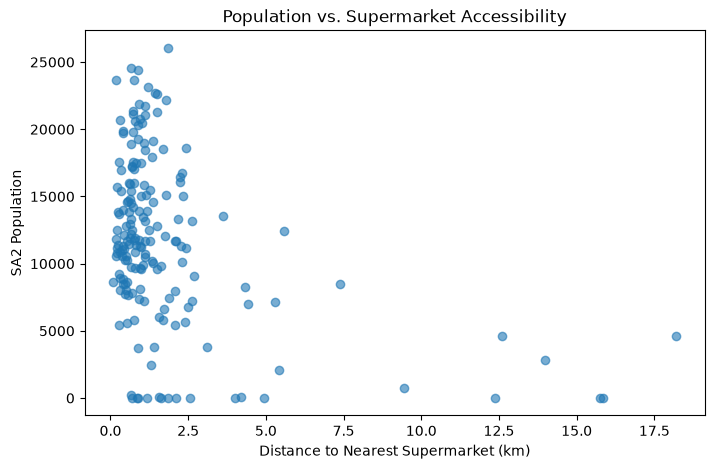

In [101]:
plt.figure(figsize=(8, 5))

plt.scatter(
    residential_areas["distance_km"],
    residential_areas["population"],
    alpha=0.6
)

plt.xlabel("Distance to Nearest Supermarket (km)")
plt.ylabel("SA2 Population")
plt.title("Population vs. Supermarket Accessibility")

plt.show()

The scatter plot shows that most highly populated SA2 areas have relatively short distances to their nearest supermarket, while areas with greater distances generally have smaller populations.

This suggests that some geographically isolated areas may have fewer residents affected by limited supermarket access. However, further socioeconomic and transportation analysis is needed to identify potentially underserved communities.

In [102]:
rho, p_value = spearmanr(
    residential_areas["population"],
    residential_areas["distance_km"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

Spearman correlation: -0.251
P-value: 0.0007


Spearman's correlation identified a weak but statistically significant negative relationship between SA2 population and distance to the nearest supermarket (ρ = −0.251, p = 0.0007).

This suggests that more populated areas generally have shorter distances to supermarkets, supporting the pattern observed in the scatter plot.

However, the weak correlation indicates that population alone does not fully explain differences in geographic accessibility.

# 3. Income Distribution Analysis

In [103]:
# Reuse the same ZIP file from population analysis
with zipfile.ZipFile(zip_path) as z:
    file = next(
        name for name in z.namelist()
        if "G02" in name.upper()
        and "SA2" in name.upper()
        and name.lower().endswith(".csv")
    )

    income = pd.read_csv(z.open(file))

print(income.shape)
print(income.columns.tolist())
display(income.head())

(267, 9)
['SA2_CODE_2021', 'Median_age_persons', 'Median_mortgage_repay_monthly', 'Median_tot_prsnl_inc_weekly', 'Median_rent_weekly', 'Median_tot_fam_inc_weekly', 'Average_num_psns_per_bedroom', 'Median_tot_hhd_inc_weekly', 'Average_household_size']


,SA2_CODE_2021,Median_age_persons,Median_mortgage_repay_monthly,Median_tot_prsnl_inc_weekly,Median_rent_weekly,Median_tot_fam_inc_weekly,Average_num_psns_per_bedroom,Median_tot_hhd_inc_weekly,Average_household_size
0,501011001,46,1816,705,300,1693,0.8,1370,2.4
1,501011003,43,1993,880,420,2130,0.8,1823,2.6
2,501011004,40,1700,851,380,1986,0.8,1678,2.6
3,501011293,46,1733,717,360,1759,0.7,1381,2.4
4,501011294,45,1733,701,350,1740,0.7,1351,2.4


In [104]:
print("Dataset shape:", income.shape)

print("\nMissing values:")
print(income[["SA2_CODE_2021", "Median_tot_hhd_inc_weekly"]].isna().sum())

print("\nDuplicate SA2 codes:")
print(income["SA2_CODE_2021"].duplicated().sum())

print("\nIncome data type:")
print(income["Median_tot_hhd_inc_weekly"].dtype)

print("\nIncome summary:")
print(income["Median_tot_hhd_inc_weekly"].describe())

Dataset shape: (267, 9)

Missing values:
SA2_CODE_2021                0
Median_tot_hhd_inc_weekly    0
dtype: int64

Duplicate SA2 codes:
0

Income data type:
int64

Income summary:
count     267.000000
mean     1746.288390
std       643.521949
min         0.000000
25%      1364.000000
50%      1749.000000
75%      2123.500000
max      4799.000000
Name: Median_tot_hhd_inc_weekly, dtype: float64


In [105]:
income_clean = income[
    ["SA2_CODE_2021", "Median_tot_hhd_inc_weekly"]
].copy()

income_clean = income_clean.rename(columns={
    "SA2_CODE_2021": "SA2_CODE21",
    "Median_tot_hhd_inc_weekly": "median_weekly_income"
})

income_clean.head()

,SA2_CODE21,median_weekly_income
0,501011001,1370
1,501011003,1823
2,501011004,1678
3,501011293,1381
4,501011294,1351


In [106]:
# Check areas reporting zero household income
print("Zero-income areas:", (income_clean["median_weekly_income"] == 0).sum())

display(
    income_clean[income_clean["median_weekly_income"] == 0]
)

Zero-income areas: 9


,SA2_CODE21,median_weekly_income
92,505021087,0
123,506011111,0
133,506021120,0
134,506021121,0
165,507011151,0
218,509011235,0
253,511031281,0
256,511031284,0
266,599999499,0


Nine SA2 areas reported a median weekly household income of zero. These records were investigated alongside population data to distinguish unpopulated areas from potentially unavailable income information. Zero-income values will not automatically be treated as indicators of socioeconomic disadvantage.

In [107]:
income_clean["SA2_CODE21"] = income_clean["SA2_CODE21"].astype(str)
population_clean["SA2_CODE21"] = population_clean["SA2_CODE21"].astype(str)

zero_income_check = income_clean[
    income_clean["median_weekly_income"] == 0
].merge(
    population_clean,
    on="SA2_CODE21",
    how="left"
)

display(zero_income_check)

,SA2_CODE21,median_weekly_income,population
0,505021087,0,0
1,506011111,0,3
2,506021120,0,0
3,506021121,0,20
4,507011151,0,0
5,509011235,0,0
6,511031281,0,0
7,511031284,0,0
8,599999499,0,8055


The dataset contains 267 SA2 records with no missing values or duplicate identifiers.

Nine areas reported zero median weekly household income. Further investigation showed that six had no recorded population, two had very small populations, and one represented people with no usual address.

These zero-income values were treated as unavailable rather than indicators of low household income to avoid misleading conclusions.

In [108]:
# Ensure SA2 identifiers have the same data type
perth_accessibility["SA2_CODE21"] = perth_accessibility["SA2_CODE21"].astype(str)
income_clean["SA2_CODE21"] = income_clean["SA2_CODE21"].astype(str)

# Merge household income with population and supermarket distance
perth_income_access = perth_accessibility.merge(
    income_clean,
    on="SA2_CODE21",
    how="left",
    validate="one_to_one"
)

# Verify the merge
print("Total SA2 areas:", len(perth_income_access))
print("Missing income:", perth_income_access["median_weekly_income"].isna().sum())

perth_income_access[
    ["SA2_NAME21", "population", "distance_km", "median_weekly_income"]
].head()

Total SA2 areas: 185
Missing income: 0


,SA2_NAME21,population,distance_km,median_weekly_income
0,Dawesville - Bouvard,8498,7.382523,1436
1,Falcon - Wannanup,9664,0.779720,1294
2,Greenfields,9869,1.055387,1004
3,Halls Head - Erskine,19905,0.394925,1377
4,Mandurah,10256,0.481644,901


In [109]:
income_analysis = perth_income_access[
    (perth_income_access["population"] > 0)
    & (perth_income_access["median_weekly_income"].notna())
    & (perth_income_access["distance_km"].notna())
].copy()

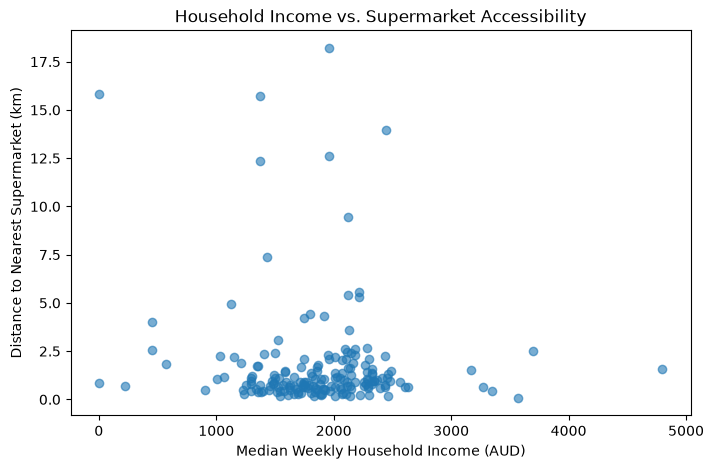

In [110]:
plt.figure(figsize=(8, 5))

plt.scatter(
    income_analysis["median_weekly_income"],
    income_analysis["distance_km"],
    alpha=0.6
)

plt.xlabel("Median Weekly Household Income (AUD)")
plt.ylabel("Distance to Nearest Supermarket (km)")
plt.title("Household Income vs. Supermarket Accessibility")

plt.show()

In [111]:
rho, p_value = spearmanr(
    income_analysis["median_weekly_income"],
    income_analysis["distance_km"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

Spearman correlation: 0.040
P-value: 0.5947


Spearman's correlation found no statistically significant relationship between median weekly household income and distance to the nearest supermarket (ρ = 0.040, p = 0.5947).

This suggests that household income is not strongly associated with geographic supermarket distance in our current analysis.

Unlike population, which showed a weak but statistically significant negative association, household income showed little evidence of a consistent relationship.

However, household income may still influence food accessibility through transportation costs and grocery affordability, which are not captured by straight-line distance alone.

# 4. Transport Access Analysis

In [112]:
# Load vehicle ownership data
with zipfile.ZipFile(zip_path) as z:
    file = next(
        name for name in z.namelist()
        if "G34" in name.upper()
        and "SA2" in name.upper()
        and name.lower().endswith(".csv")
    )

    transport = pd.read_csv(z.open(file))

print(transport.shape)
print(transport.columns.tolist())

transport.head()

(267, 9)
['SA2_CODE_2021', 'Num_MVs_per_dweling_0_MVs', 'Num_MVs_per_dweling_1_MVs', 'Num_MVs_per_dweling_2_MVs', 'Num_MVs_per_dweling_3_MVs', 'Num_MVs_per_dweling_4mo_MVs', 'Num_MVs_per_dweling_Tot', 'Num_MVs_NS', 'Total_dwelings']


,SA2_CODE_2021,Num_MVs_per_dweling_0_MVs,Num_MVs_per_dweling_1_MVs,Num_MVs_per_dweling_2_MVs,Num_MVs_per_dweling_3_MVs,Num_MVs_per_dweling_4mo_MVs,Num_MVs_per_dweling_Tot,Num_MVs_NS,Total_dwelings
0,501011001,45,669,1055,378,204,2350,48,2399
1,501011003,43,1120,1812,639,369,3982,72,4055
2,501011004,95,1120,1522,463,220,3423,63,3487
3,501011293,146,1274,1426,482,231,3559,54,3616
4,501011294,282,2685,2793,945,491,7185,102,7292


In [113]:
print("Missing values:")
print(transport.isna().sum())

print("\nDuplicate SA2 codes:")
print(transport["SA2_CODE_2021"].duplicated().sum())

print("\nZero denominators:")
print((transport["Num_MVs_per_dweling_Tot"] == 0).sum())

Missing values:
SA2_CODE_2021                  0
Num_MVs_per_dweling_0_MVs      0
Num_MVs_per_dweling_1_MVs      0
Num_MVs_per_dweling_2_MVs      0
Num_MVs_per_dweling_3_MVs      0
Num_MVs_per_dweling_4mo_MVs    0
Num_MVs_per_dweling_Tot        0
Num_MVs_NS                     0
Total_dwelings                 0
dtype: int64

Duplicate SA2 codes:
0

Zero denominators:
16


In [117]:
transport_clean = transport[
    [
        "SA2_CODE_2021",
        "Num_MVs_per_dweling_0_MVs",
        "Num_MVs_per_dweling_Tot"
    ]
].copy()

transport_clean = transport_clean.rename(columns={
    "SA2_CODE_2021": "SA2_CODE21"
})

transport_clean["SA2_CODE21"] = transport_clean["SA2_CODE21"].astype(str)

transport_clean["pct_no_vehicle"] = (
    transport_clean["Num_MVs_per_dweling_0_MVs"] /
    transport_clean["Num_MVs_per_dweling_Tot"].replace(0, np.nan)
) * 100

In [118]:
# Merge vehicle ownership with accessibility data
perth_transport = perth_accessibility.merge(
    transport_clean[["SA2_CODE21", "pct_no_vehicle"]],
    on="SA2_CODE21",
    how="left",
    validate="one_to_one"
)

# Keep populated areas with valid observations
transport_analysis = perth_transport[
    (perth_transport["population"] > 0)
    & (perth_transport["pct_no_vehicle"].notna())
    & (perth_transport["distance_km"].notna())
].copy()

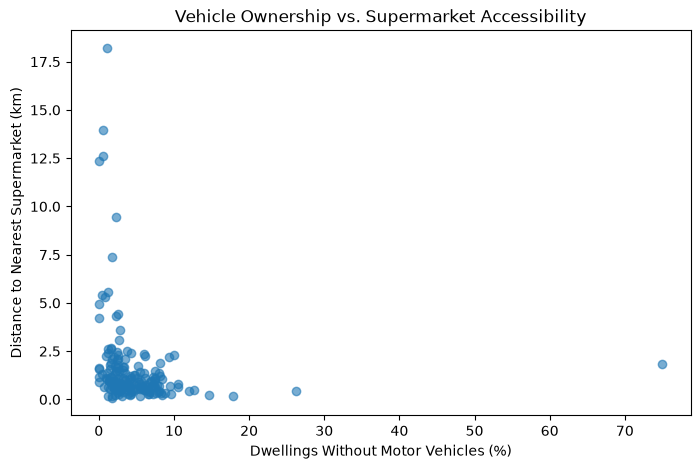

In [119]:
plt.figure(figsize=(8, 5))

plt.scatter(
    transport_analysis["pct_no_vehicle"],
    transport_analysis["distance_km"],
    alpha=0.6
)

plt.xlabel("Dwellings Without Motor Vehicles (%)")
plt.ylabel("Distance to Nearest Supermarket (km)")
plt.title("Vehicle Ownership vs. Supermarket Accessibility")

plt.show()

In [120]:
rho, p_value = spearmanr(
    transport_analysis["pct_no_vehicle"],
    transport_analysis["distance_km"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

Spearman correlation: -0.408
P-value: 0.0000


Spearman's correlation identified a moderate, statistically significant negative relationship between the percentage of dwellings without motor vehicles and supermarket distance (ρ = −0.408, p < 0.0001).

This suggests that areas with higher proportions of car-free dwellings tend to be closer to supermarkets, potentially reflecting differences between urban and outer suburban communities.

However, proximity alone does not guarantee accessibility, as public transport availability and walkability were not considered.